# Worked studies: perturb, compare and interpret

Four compact studies connect the main DNAscape workflows: a masked origin-firing perturbation, covariate modulation, a fork-speed sweep and periodic replication. Each study uses synthetic inputs so that the assumptions remain explicit.

Run cells in order with DNAscape installed. No downloads are needed. Results go to `examples/outputs/studies/`.

1. Suppress origin firing in selected regions
2. Modulate initiation with a prepared covariate
3. Compare fork-speed hypotheses and analyse profiles
4. Replicate a periodic domain


In [1]:
from pathlib import Path
import os
import sys

# Works with Jupyter started in the repository root or in examples/.
PROJECT_DIR = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "dnascape" / "__init__.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start Jupyter inside your DNAscape checkout.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
OUTPUT_DIR = (
    Path(
        os.environ.get("DNASCAPE_NOTEBOOK_OUTPUT", PROJECT_DIR / "examples" / "outputs")
    )
    / "studies"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dnascape import rmap, rsim, rsave, plotf
from dnascape.workflows import (
    DataFilterSettings,
    ProfileModulationSettings,
    apply_data_filter,
)
from dnascape.workflows.analysis import (
    AnalysisDataset,
    SmoothingSettings,
    smooth_profile,
    analyse_profiles,
    export_correlation_report,
)

plt.rcParams.update(
    {
        "figure.figsize": (8, 3.2),
        "figure.dpi": 100,
        "axes.grid": False,
        "font.size": 10,
        "axes.prop_cycle": plt.cycler(color=["#b03412", "#3498b8", "#68615b"]),
    }
)
print(f"Outputs: {OUTPUT_DIR}")


Outputs: C:\Users\Francisco Berkemeier\Dropbox\Main Work\PostDoc\My Papers\DNAscape\github\DNAscape-devmode\examples\outputs\studies


## 1. Suppress origin firing in selected regions

Build a small reference profile and set potential initiation to zero inside two masks. Genomic coordinates passed to the region-transform function are in **kb**, while the position ranges below are explicitly in **bp**. Forks can still enter and passively replicate the masked region.


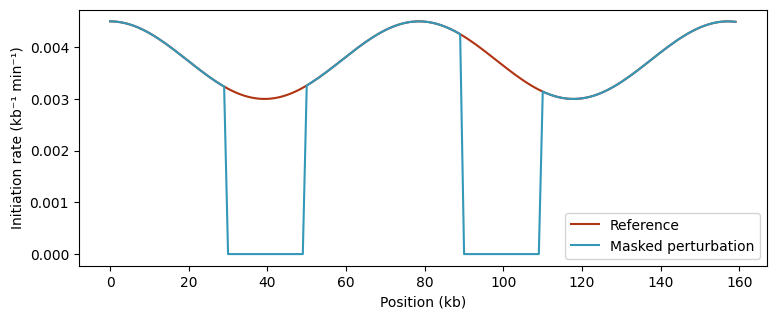

In [2]:
DX_KB = 1.0
positions_kb = np.arange(160) * DX_KB
ir_density = 0.003 * (1.0 + 0.5 * np.cos(positions_kb / 25.0) ** 2)
mask_settings = DataFilterSettings(
    enabled=True,
    selection="ranges",
    position_ranges="(30000,50000), (90000,110000)",
    profile_units="bp",
    action="replace",
    value=0.0,
)
suppressed_ir = apply_data_filter(ir_density, mask_settings, positions=positions_kb)
mask = ((positions_kb >= 30) & (positions_kb < 50)) | (
    (positions_kb >= 90) & (positions_kb < 110)
)
assert np.all(suppressed_ir[mask] == 0)
np.testing.assert_array_equal(suppressed_ir[~mask], ir_density[~mask])
plotf(
    ir_density,
    suppressed_ir,
    x_array=positions_kb,
    labels=["Reference", "Masked perturbation"],
    xtitle="Position (kb)",
    ytitle="Initiation rate (kb⁻¹ min⁻¹)",
    figsize=(8, 3.2),
)


### Compare stochastic outcomes

The same seed makes rerunning each model reproducible. Different initiation landscapes can still consume random numbers differently, so this is not a fully paired per-cell experiment. Compare ensemble summaries and increase the replicate count for quantitative inference.


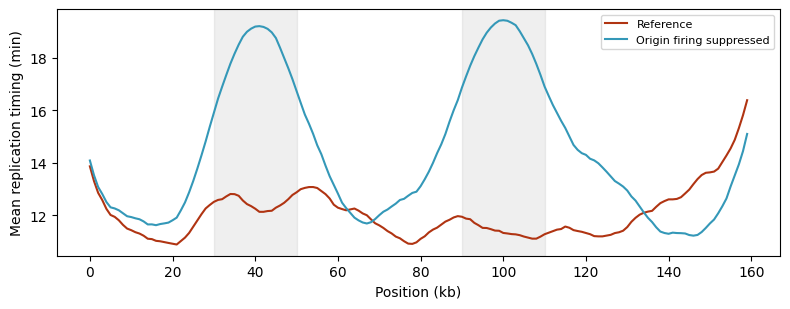

In [3]:
base_settings = {
    "resolution_x": DX_KB,
    "sim_number": 48,
    "seed": 31,
    "time_statsQ": True,
    "time_grid": np.arange(0.0, 301.0, 5.0),
    "max_rep_time": 600.0,
    "verbose": False,
}
reference = rsim(
    source={"initiation_rate": ir_density * DX_KB, "fork_speed": 1.4},
    assumptions=base_settings,
)
perturbed = rsim(
    source={"initiation_rate": suppressed_ir * DX_KB, "fork_speed": 1.4},
    assumptions=base_settings,
)
fig, ax = plt.subplots()
ax.plot(positions_kb, reference["replication_timing"], label="Reference")
ax.plot(positions_kb, perturbed["replication_timing"], label="Origin firing suppressed")
for start, end in [(30, 50), (90, 110)]:
    ax.axvspan(start, end, color="grey", alpha=0.12)
ax.set(xlabel="Position (kb)", ylabel="Mean replication timing (min)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 2. Modulate initiation with a prepared covariate

An aligned genomic profile can modulate replication kinetics through an explicit formula. Here a synthetic covariate stands in for a prepared gene-location, ChIP-seq or other assay profile. This is a hypothesis about its effect, not a causal relationship inferred from the covariate alone.

`source` means the current initiation signal; `profile` means the covariate. Only the selected mask changes.


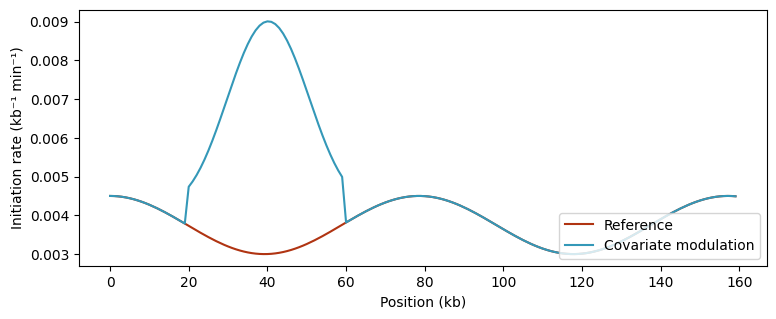

In [4]:
covariate = np.exp(-0.5 * ((positions_kb - 40.0) / 10.0) ** 2)
modulation = ProfileModulationSettings(
    operation="expression", values=covariate, expression="source * (1 + 2 * profile)"
)
modulated_ir = apply_data_filter(
    ir_density,
    DataFilterSettings(
        enabled=True,
        selection="ranges",
        position_ranges="(20000,60000)",
        profile_units="bp",
        action="modulate",
        modulation=modulation,
    ),
    positions=positions_kb,
)
assert np.all(modulated_ir >= ir_density)
plotf(
    ir_density,
    modulated_ir,
    x_array=positions_kb,
    labels=["Reference", "Covariate modulation"],
    xtitle="Position (kb)",
    ytitle="Initiation rate (kb⁻¹ min⁻¹)",
    figsize=(8, 3.2),
)


## 3. Compare fork-speed hypotheses and analyse profiles

A short parameter sweep holds initiation fixed and compares three constant fork speeds. Record the parameter and seed with every result. A box plot summarises completion-time distributions without hiding replicate variation.


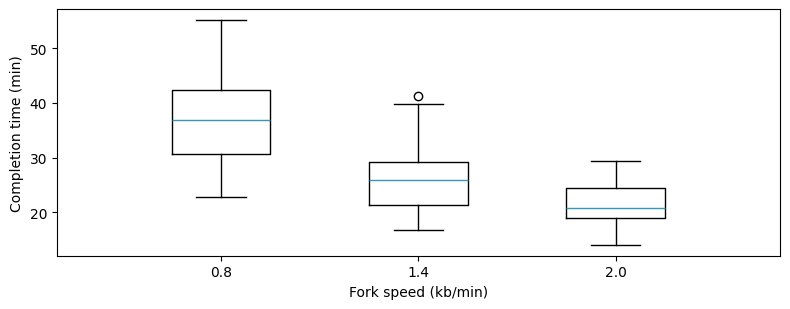

,Fork speed (kb/min),Mean completion (min),Mean fired origins
0,0.8,36.63,9.65
1,1.4,25.97,7.52
2,2.0,21.56,6.25


In [5]:
speed_sweep = {}
for index, speed in enumerate((0.8, 1.4, 2.0)):
    speed_sweep[speed] = rsim(
        source={"initiation_rate": ir_density * DX_KB, "fork_speed": speed},
        assumptions={**base_settings, "seed": 40 + index},
    )
summary = pd.DataFrame(
    [
        {
            "Fork speed (kb/min)": speed,
            "Mean completion (min)": np.mean(result["completion_time"]),
            "Mean fired origins": np.mean(result["num_origins"]),
        }
        for speed, result in speed_sweep.items()
    ]
)
fig, ax = plt.subplots()
ax.boxplot(
    [result["completion_time"] for result in speed_sweep.values()],
    positions=list(speed_sweep),
    widths=0.3,
)
ax.set(
    xticks=list(speed_sweep),
    xlabel="Fork speed (kb/min)",
    ylabel="Completion time (min)",
)
fig.tight_layout()
plt.show()
summary.round(2)


### Correlations and analysis on masked regions

The analysis workflow supports Pearson, Spearman and Kendall correlations. Compare matched positions and retain pairwise finite-sample counts. For analysis on a mask, replace unselected entries with NaN **in analysis copies**, preserving the full genomic grid. Smoothing below uses finite-sample weights at the edges.


In [6]:
datasets = []
for name, result in [("Reference", reference), ("Perturbed", perturbed)]:
    values = smooth_profile(
        np.asarray(result["replication_timing"]),
        SmoothingSettings(method="moving_average", window=5),
    )
    datasets.append(AnalysisDataset(name, values))
report = analyse_profiles(datasets, methods=("pearson", "spearman", "kendall"))
masked_report = analyse_profiles(
    [
        AnalysisDataset(item.name, np.where(mask, item.values, np.nan))
        for item in datasets
    ],
    methods=("pearson", "spearman"),
)
(OUTPUT_DIR / "correlations.tsv").write_bytes(
    export_correlation_report(report, file_format="tsv")
)
(OUTPUT_DIR / "correlations_on_mask.tsv").write_bytes(
    export_correlation_report(masked_report, file_format="tsv")
)
pd.DataFrame(
    [
        {
            "Method": item.method,
            "All positions": item.coefficients[0, 1],
            "Paired positions": item.sample_counts[0, 1],
        }
        for item in report.matrices
    ]
)


,Method,All positions,Paired positions
0,pearson,-0.076365,160
1,spearman,-0.036456,160
2,kendall,-0.024371,160


## 4. Replicate a periodic domain

A periodic domain has no privileged end: moving forks wrap across the join. Use a smoothly periodic initiation landscape, and keep this physical choice separate from the circular display in the [plotting notebook](5-plotting.ipynb).

The forward deterministic map uses rate per kb; the simulator uses rate per bin. Both calls below use the same genomic length and kinetic units.


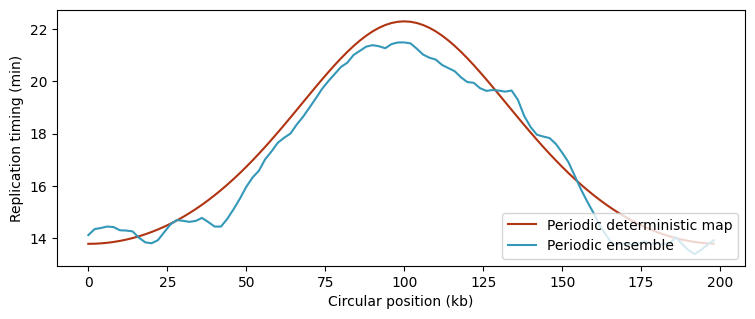

In [7]:
circle_dx = 2.0
circle_positions = np.arange(100) * circle_dx
circle_ir = 0.002 * (
    1.0 + 0.5 * np.cos(2 * np.pi * circle_positions / (100 * circle_dx))
)
circle_timing = rmap(
    {"initiation_rate": circle_ir, "fork_speed": 1.4},
    "replication_timing",
    assumptions={"resolution_x": circle_dx, "perQ": True, "verbose": False},
)
circle_sim = rsim(
    source={"initiation_rate": circle_ir * circle_dx, "fork_speed": 1.4},
    assumptions={**base_settings, "resolution_x": circle_dx, "perQ": True, "seed": 51},
)
plotf(
    circle_timing,
    circle_sim["replication_timing"],
    x_array=circle_positions,
    labels=["Periodic deterministic map", "Periodic ensemble"],
    xtitle="Circular position (kb)",
    ytitle="Replication timing (min)",
    figsize=(8, 3.2),
)


### Save the study inputs and outputs

Masks export as integer positions in bp. Keep the reference and perturbed inputs alongside the outcomes so that every comparison can be reproduced.


In [8]:
np.savetxt(
    OUTPUT_DIR / "suppression_mask_bp.txt",
    np.rint(positions_kb[mask] * 1000).astype(int),
    fmt="%d",
)
rsave(summary, OUTPUT_DIR / "fork_speed_sweep.tsv")
np.savez_compressed(
    OUTPUT_DIR / "perturbation_study.npz",
    positions_kb=positions_kb,
    resolution_kb=DX_KB,
    seed=base_settings["seed"],
    initiation_reference_per_kb_min=ir_density,
    initiation_suppressed_per_kb_min=suppressed_ir,
    initiation_modulated_per_kb_min=modulated_ir,
    timing_reference_min=reference["replication_timing"],
    timing_perturbed_min=perturbed["replication_timing"],
)
print("Saved study arrays, parameter sweep, masks and correlation reports")


Saved study arrays, parameter sweep, masks and correlation reports


Try changing one mechanism at a time: mask width, modulation formula, fork speed or geometry. Check absolute differences and uncertainty as well as correlations. The [mapping atlas](2-mapping.ipynb) and [simulation notebook](3-simulation.ipynb) describe the underlying models.
